# Statistical analysis for classification models

## Environment

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

## Loading result dataframes

In [52]:
# Models dictionary
models_dict = {
    "Random Forest": pd.read_csv("output/random_forest_results.csv"),
    "QDA": pd.read_csv("output/qda_results.csv"),
    "Logistic Regression": pd.read_csv("output/logistic_regression_results.csv"),
    "KNN": pd.read_csv("output/knn_results.csv"),
    "XGBoost": pd.read_csv("output/xgboost_results.csv"),
}

# Metric list
metrics = [
    "balanced_accuracy",
    "accuracy",
    "f1_score_macro",
    "f1_score_micro",
    "hamming_loss",
]


# Number of runs
n = models_dict["Random Forest"].shape[0]

# Significance level
alpha = 0.05

# t-quantile for the given alpha and degrees of freedom
t_quantile = stats.t.ppf(1 - alpha / 2, df=n - 1)

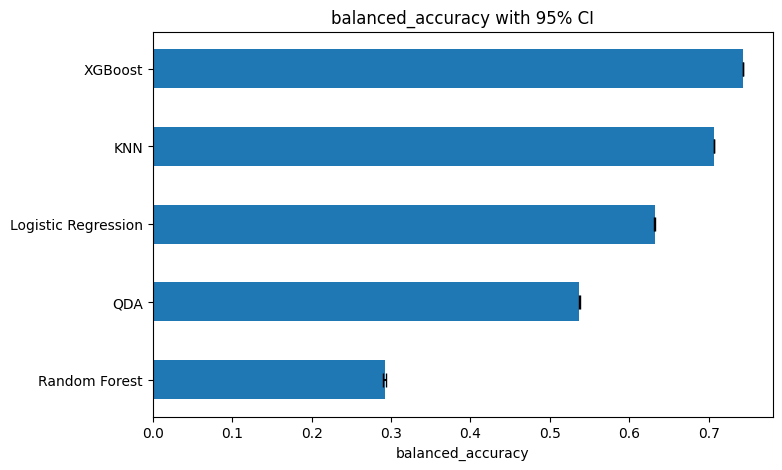

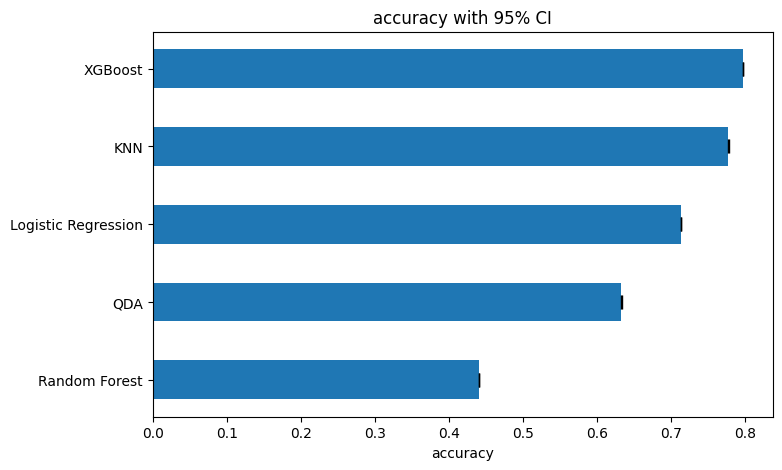

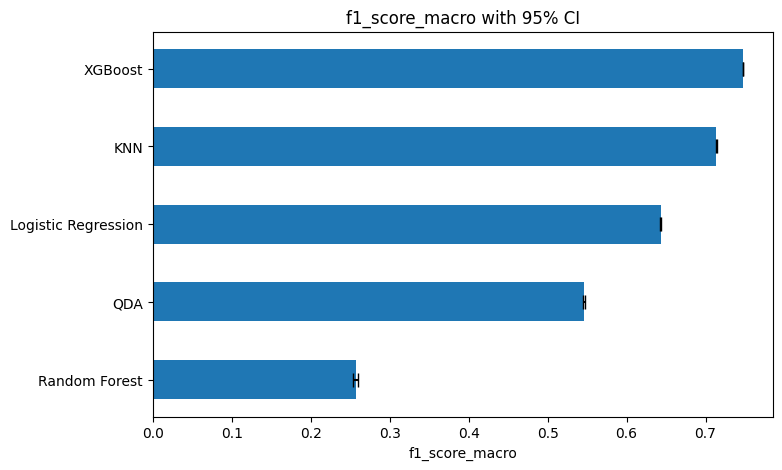

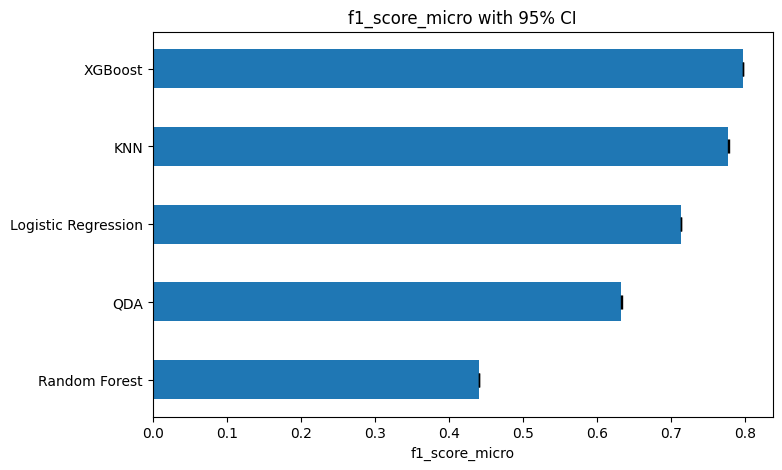

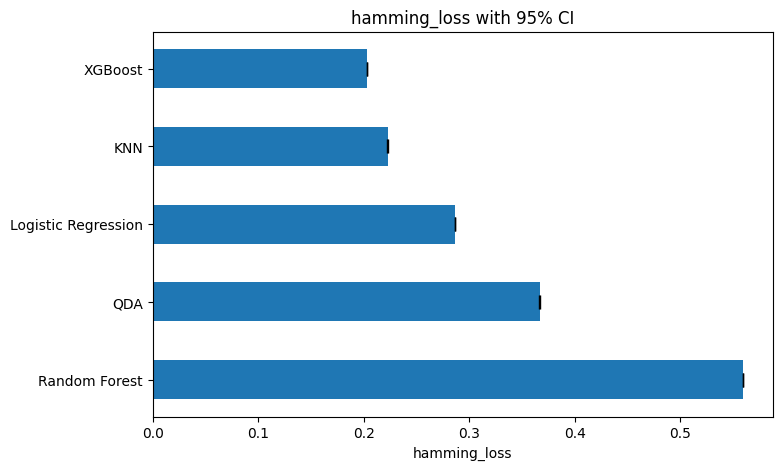

In [53]:
for metric in metrics:
    means = [models_dict[m][metric].mean() for m in models_dict.keys()]
    stds = [models_dict[m][metric].std() for m in models_dict.keys()]

    ci_lower = means - t_quantile * (stds / np.sqrt(n))
    ci_upper = means + t_quantile * (stds / np.sqrt(n))

    plt.figure(figsize=(8, 5))
    plt.barh(
        list(models_dict.keys()),
        means,
        xerr=[means - ci_lower, ci_upper - means],
        capsize=5,
        height=0.5,
    )
    plt.xlabel(metric)
    plt.title(f"{metric} with 95% CI")
    plt.show()

## Table overview

In [66]:
# Initialize summary table
summary_table = pd.DataFrame()

rows = list()
# Create a depivoted table.
for model_name, df in models_dict.items():
    rows = []
    for model_name, df in models_dict.items():
        for metric in metrics:
            mean = df[metric].mean()
            std = df[metric].std(ddof=1)
            ci_lower = mean - t_quantile * (std / np.sqrt(n))
            ci_upper = mean + t_quantile * (std / np.sqrt(n))
            ci95 = f"[{ci_lower:.3f}, {ci_upper:.3f}]"

            rows.append(
                {
                    "Model": model_name,
                    "Metric": metric,
                    "mean": mean,
                    "std": std,
                    "ci95": ci95,
                }
            )

summary_multi = pd.DataFrame(rows)

# Pivot for better visualization
summary_multi = summary_multi.set_index(["Model", "Metric"])
# summary_multi.MultiIndex.from_frame(['Model', 'Metric'], inplace=True)

print(summary_multi)

                                           mean       std            ci95
Model               Metric                                               
Random Forest       balanced_accuracy  0.292014  0.004424  [0.290, 0.294]
                    accuracy           0.440392  0.000745  [0.440, 0.441]
                    f1_score_macro     0.257323  0.008308  [0.254, 0.260]
                    f1_score_micro     0.440392  0.000745  [0.440, 0.441]
                    hamming_loss       0.559608  0.000745  [0.559, 0.560]
QDA                 balanced_accuracy  0.536967  0.001812  [0.536, 0.538]
                    accuracy           0.632890  0.001238  [0.632, 0.633]
                    f1_score_macro     0.546123  0.001884  [0.545, 0.547]
                    f1_score_micro     0.632890  0.001238  [0.632, 0.633]
                    hamming_loss       0.367110  0.001238  [0.367, 0.368]
Logistic Regression balanced_accuracy  0.631719  0.001047  [0.631, 0.632]
                    accuracy          